In [1]:
import pandas as pd

df = pd.read_csv("data/processed/feature_engineered.csv")

print(df.shape)
df.head()

(100000, 103)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID,dropped_call_rate,overage_ratio,revenue_per_minute
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,U,U,U,U,Y,361.0,1000001,0.012500,0.000000,0.108956
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,U,U,U,U,Y,240.0,1000002,0.031526,0.155576,0.118848
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,Y,U,U,U,Y,1504.0,1000003,0.033333,0.000000,1.510222
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,U,U,U,U,Y,1812.0,1000004,0.000000,0.000000,4.470588
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,U,U,U,U,Y,434.0,1000005,0.043284,0.000000,0.096640


In [2]:
X = df.drop(columns=["churn"])
y = df["churn"]

# Remove customer ID if present
X = X.drop(columns=["Customer_ID"], errors="ignore")

print(X.shape)
print(y.value_counts())

(100000, 101)
churn
0    50438
1    49562
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(80000, 101) (20000, 101)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [5]:
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Training completed!")

Training completed!


In [6]:
from sklearn.metrics import accuracy_score

y_pred = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.5991


In [7]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.61865


In [8]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.5 MB/s eta 0:00:33
    --------------------------------------- 1.0/48.9 MB 1.7 MB/s eta 0:00:28
   - -------------------------------------- 1.3/48.9 MB 1.8 MB/s eta 0:00:27
   - -------------------------------------- 1.8/48.9 MB 2.0 MB/s eta 0:00:24
   - -------------------------------------- 2.4/48.9 MB 2.0 MB/s eta 0:00:24
   -- ------------------------------------- 2.9/48.9 MB 2.2 MB/s eta 0:00:22
   --- ------------------------------------ 3.9/48.9 MB 2.5 MB/s eta 0:00:19
   --- ------------------------------------ 4.7/48.9 MB 2.6 MB/s eta 0:00:17
   ---- ----------------------------------- 5.0/48.9 MB 2.7 MB/s eta 0:00:17
   ---- ----------------------------------- 5.8/48.9 MB 2.6 MB/s eta 0:00:17
   ----- ---------------------------------- 6.3/48.9 MB 2.7 MB/s eta 0:00:16
   ----- ----


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_pred))

XGBoost Accuracy: 0.6323


In [10]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, lr_model.predict(X_test)),
        accuracy_score(y_test, rf_model.predict(X_test)),
        accuracy_score(y_test, xgb_model.predict(X_test))
    ]
})

print(results.sort_values("Accuracy", ascending=False))

                 Model  Accuracy
2              XGBoost   0.63230
1        Random Forest   0.61865
0  Logistic Regression   0.59910


In [11]:
from sklearn.metrics import classification_report

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

for name, model in models.items():
    print(f"\n{name}")
    print(classification_report(y_test, model.predict(X_test)))


Logistic Regression
              precision    recall  f1-score   support

           0       0.60      0.61      0.60     10088
           1       0.60      0.59      0.59      9912

    accuracy                           0.60     20000
   macro avg       0.60      0.60      0.60     20000
weighted avg       0.60      0.60      0.60     20000


Random Forest
              precision    recall  f1-score   support

           0       0.63      0.60      0.61     10088
           1       0.61      0.63      0.62      9912

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000


XGBoost
              precision    recall  f1-score   support

           0       0.64      0.62      0.63     10088
           1       0.62      0.65      0.63      9912

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.63      

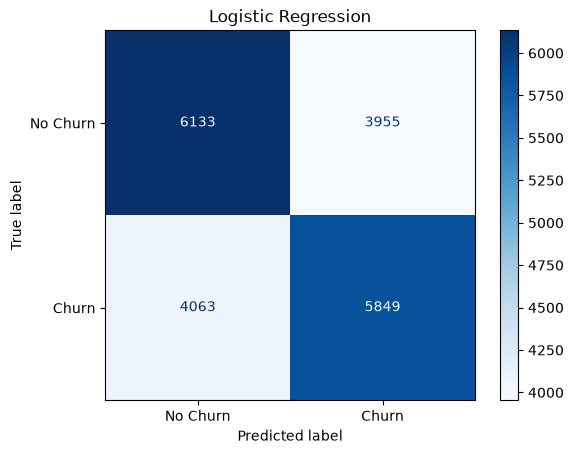

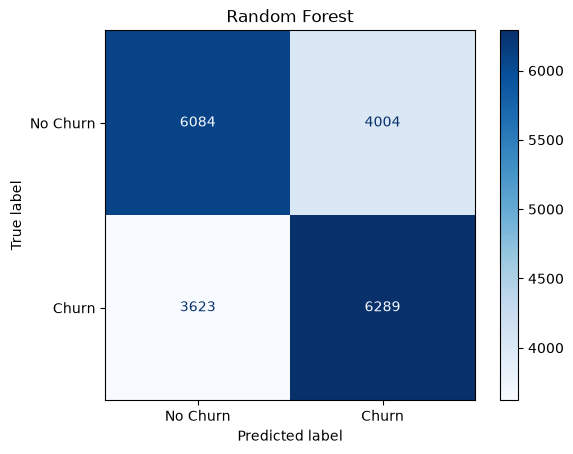

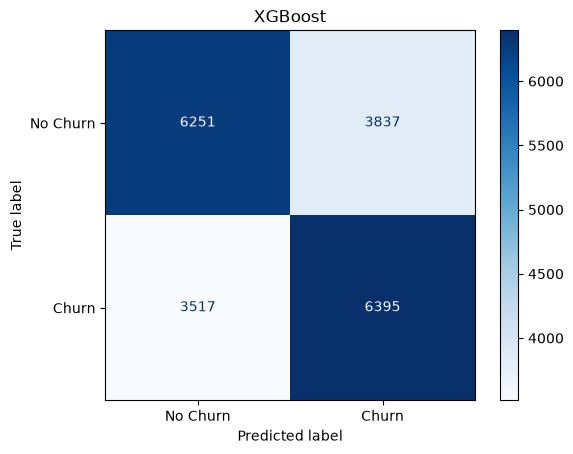

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test),
        display_labels=["No Churn", "Churn"],
        cmap="Blues"
    )
    plt.title(name)
    plt.show()

In [14]:
print(xgb_model.named_steps.keys())

dict_keys(['preprocessor', 'model'])


In [16]:
from sklearn.model_selection import RandomizedSearchCV

# Automatically find the XGBoost step name
step_name = list(xgb_model.named_steps.keys())[-1]
print("XGBoost step:", step_name)

params = {
    f"{step_name}__n_estimators": [100, 200],
    f"{step_name}__max_depth": [3, 5, 7],
    f"{step_name}__learning_rate": [0.03, 0.1],
    f"{step_name}__subsample": [0.8, 1.0]
}

search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=params,
    n_iter=6,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV F1:", search.best_score_)

XGBoost step: model
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Best CV F1: 0.6389138346231568


In [17]:
best_model = search.best_estimator_

from sklearn.metrics import classification_report

y_pred_tuned = best_model.predict(X_test)

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.64      0.63      0.64     10088
           1       0.63      0.64      0.64      9912

    accuracy                           0.64     20000
   macro avg       0.64      0.64      0.64     20000
weighted avg       0.64      0.64      0.64     20000



                     Feature  Importance
76              num__eqpdays    0.030351
166        cat__refurb_new_N    0.020677
48               num__months    0.019995
66            num__hnd_price    0.013275
1              num__mou_Mean    0.012814
104         cat__crclscod_EA    0.012355
219            cat__ethnic_Z    0.012146
213            cat__ethnic_O    0.011969
136          cat__asl_flag_N    0.011823
2           num__totmrc_Mean    0.010564
49             num__uniqsubs    0.010537
179           cat__marital_U    0.010313
230          cat__creditcd_N    0.009933
78        num__overage_ratio    0.009871
79   num__revenue_per_minute    0.009656


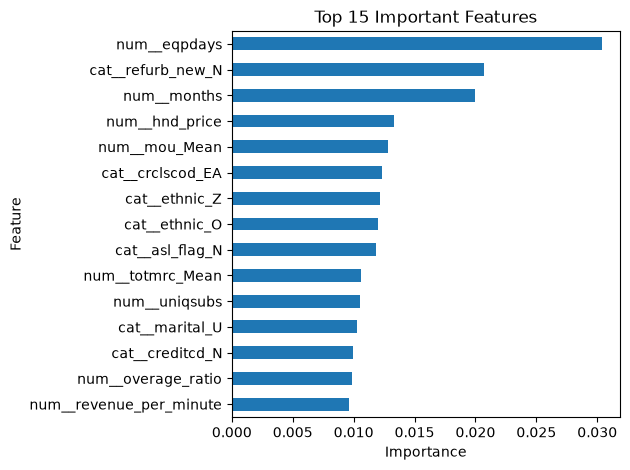

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

xgb_step = list(best_model.named_steps.keys())[-1]
xgb = best_model.named_steps[xgb_step]

feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
).head(15)

print(importance)

importance.sort_values("Importance").plot(
    x="Feature", y="Importance",
    kind="barh", legend=False
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [19]:
%pip install shap

   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.0 MB ? eta -:--:--
    --------------------------------------- 0.8/43.0 MB 1.8 MB/s eta 0:00:24
    --------------------------------------- 1.0/43.0 MB 1.8 MB/s eta 0:00:23
   - -------------------------------------- 1.6/43.0 MB 1.9 MB/s eta 0:00:22
   - -------------------------------------- 2.1/43.0 MB 2.0 MB/s eta 0:00:20
   -- ------------------------------------- 2.9/43.0 MB 2.3 MB/s eta 0:00:18
   --- ------------------------------------ 3.4/43.0 MB 2.4 MB/s eta 0:00:17
   --- ------------------------------------ 3.9/43.0 MB 2.4 MB/s eta 0:00:17
   ---- ----------------------------------- 4.5/43.0 MB 2.5 MB/s eta 0:00:16
   ---- ----------------------------------- 5.2/43.0 MB 2.6 MB/s eta 0:00:15
   ----- ---------------------------------- 6.0/43.0 MB 2.7 MB/s eta 0:00:14
   ------ --------------------------------- 6.6/43.0 MB 2.7 MB/s eta 0:00:14
   ------ ---


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import shap

xgb_step = list(best_model.named_steps.keys())[-1]
xgb = best_model.named_steps[xgb_step]

# Use a small sample to keep it fast
X_sample = X_test.sample(200, random_state=42)

X_transformed = best_model.named_steps["preprocessor"].transform(X_sample)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(X_transformed)

shap_values.feature_names = feature_names

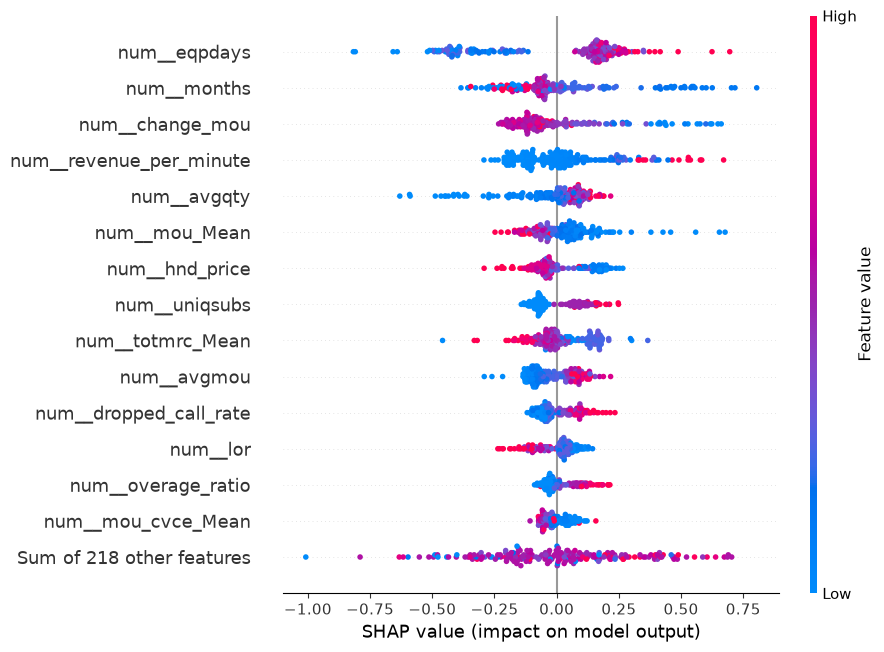

In [22]:
shap.plots.beeswarm(shap_values, max_display=15)

In [24]:
import os
print(os.getcwd())

C:\Users\aayus


In [25]:
import joblib

joblib.dump(best_model, "churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [26]:
import os

print(os.path.exists("churn_model.pkl"))

True


In [27]:
import joblib

loaded_model = joblib.load("churn_model.pkl")

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0][1]

print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn probability:", round(probability * 100, 2), "%")

Prediction: Churn
Churn probability: 72.78 %
